# Analyse exploratoire du catalogue Web Gallery of Art (WGA)

**Objectif.** Sélectionner les peintures et caractériser les données avant
l'entraînement du GAN.

**Plan.**
1. Chargement et vue d'ensemble
2. Qualité des données
3. Sélection des peintures (`FORM`)
4. Genre (`TYPE`)
5. École (`SCHOOL`)
6. Couverture temporelle (`TIMEFRAME`)
7. Artistes (`AUTHOR`)
8. Technique et dimensions (`TECHNIQUE`)
9. Fiabilité du champ `DATE`
10. Lieux de conservation (`LOCATION`)
11. Export du sous-ensemble peintures
12. Conclusions


In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 50)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

BLUE = "#2a78d6" 
GRAY ="#ddd9ce"   # barres non mises en avant

SRC = r"data/art_catalog.xlsx - catalog.csv"


## 1. Chargement et vue d'ensemble

**Résultat.** 52 867 lignes, 11 colonnes, aucune erreur de lecture (encodage UTF-8).


In [5]:
df = pd.read_csv(SRC)
print("Dimensions :", df.shape)
df.dtypes


Dimensions : (52867, 11)


AUTHOR       object
BORN-DIED    object
TITLE        object
DATE         object
TECHNIQUE    object
LOCATION     object
URL          object
FORM         object
TYPE         object
SCHOOL       object
TIMEFRAME    object
dtype: object

In [6]:
df.head(3)


,AUTHOR,BORN-DIED,TITLE,DATE,TECHNIQUE,LOCATION,URL,FORM,TYPE,SCHOOL,TIMEFRAME
0,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)",Venus and Adonis,1574-88,"Oil on canvas, 68 x 95 cm","Fogg Art Museum, Harvard University, Cambridge",https://www.wga.hu/html/a/aachen/adonis.html,painting,mythological,German,1601-1650
1,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)",Allegory,1598,"Oil on copper, 56 x 47 cm","Alte Pinakothek, Munich",https://www.wga.hu/html/a/aachen/allegory.html,painting,mythological,German,1601-1650
2,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)","Allegory of Peace, Art and Abundance",1602,"Oil on canvas, 197 x 142 cm","The Hermitage, St. Petersburg",https://www.wga.hu/html/a/aachen/allegorz.html,painting,mythological,German,1601-1650


## 2. Qualité des données


In [7]:
print("Valeurs NaN par colonne :")
print(df.isnull().sum())
print()
print("Chaînes vides par colonne :")
for c in df.columns:
    n = (df[c].astype(str).str.strip() == "").sum()
    if n:
        print(f"  {c}: {n}")
print()
print("Lignes dupliquées :", df.duplicated().sum())
print("URL dupliquées :", df["URL"].duplicated().sum())


Valeurs NaN par colonne :
AUTHOR       0
BORN-DIED    0
TITLE        0
DATE         0
TECHNIQUE    0
LOCATION     0
URL          0
FORM         0
TYPE         0
SCHOOL       0
TIMEFRAME    0
dtype: int64

Chaînes vides par colonne :

Lignes dupliquées : 0
URL dupliquées : 0


**Résultat.** Aucune valeur manquante, aucune chaîne vide, aucun doublon : le
catalogue est propre au niveau structurel. Les problèmes rencontrés plus loin
(section 9) relèvent d'un format hétérogène, pas de données manquantes.


## 3. Sélection des peintures (`FORM`)

**Résultat.** 32 438 peintures isolées sur 52 867 œuvres (61,4 %).


In [8]:
form_counts = df["FORM"].value_counts()
form_counts


FORM
painting         32438
sculpture         7696
architecture      4994
graphics          4289
illumination      1636
metalwork          494
mosaic             420
furniture          271
tapestry           198
ceramics           181
stained-glass      162
glassware           77
others              11
Name: count, dtype: int64

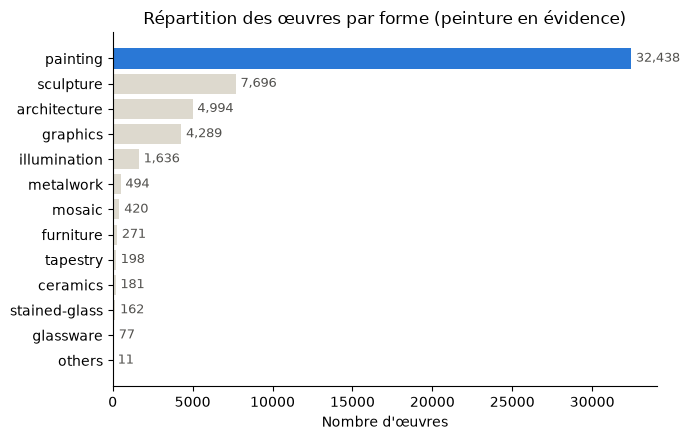

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = [BLUE if f == "painting" else GRAY for f in form_counts.index]
ax.barh(form_counts.index[::-1], form_counts.values[::-1], color=colors[::-1])
ax.set_xlabel("Nombre d'œuvres")
ax.set_title("Répartition des œuvres par forme (peinture en évidence)")
for i, v in enumerate(form_counts.values[::-1]):
    ax.text(v + 300, i, f"{v:,}", va="center", fontsize=9, color="#52514e")
plt.tight_layout()
plt.show()


In [10]:
paint = df[df["FORM"] == "painting"].copy()
n_total, n_paint = len(df), len(paint)
print(f"{n_paint:,} peintures sur {n_total:,} œuvres ({n_paint / n_total:.1%})")


32,438 peintures sur 52,867 œuvres (61.4%)


## 4. Genre (`TYPE`)


In [11]:
type_counts = paint["TYPE"].value_counts()
type_counts


TYPE
religious       13517
portrait         4810
landscape        4103
mythological     3202
genre            2772
still-life       1405
other             970
historical        943
interior          636
study              80
Name: count, dtype: int64

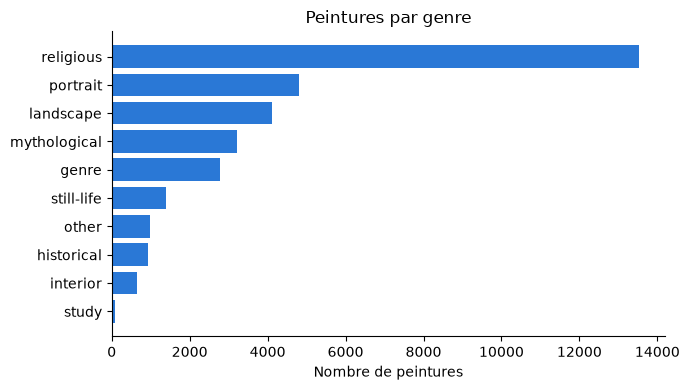

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(type_counts.index[::-1], type_counts.values[::-1], color=BLUE)
ax.set_xlabel("Nombre de peintures")
ax.set_title("Peintures par genre")
plt.tight_layout()
plt.show()


**Résultat.** La peinture religieuse domine (≈ 42 % des peintures) — cohérent
avec un corpus majoritairement antérieur au 19ᵉ siècle.


## 5. École / origine géographique (`SCHOOL`)


In [13]:
school_vc = paint["SCHOOL"].value_counts()
print(f"{school_vc.size} écoles distinctes")
school_vc.head(12)


26 écoles distinctes


SCHOOL
Italian          13743
French            4410
Dutch             4375
Flemish           3697
German            1923
Spanish           1250
English            681
Netherlandish      514
Austrian           391
Hungarian          345
American           178
Swiss              134
Name: count, dtype: int64

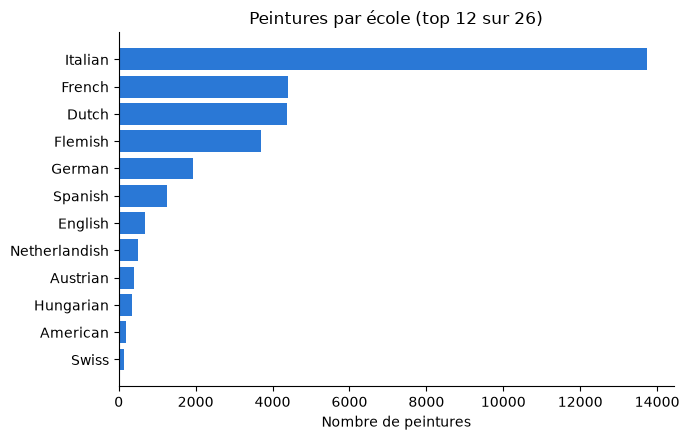

In [14]:
top = school_vc.head(12)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index[::-1], top.values[::-1], color=BLUE)
ax.set_xlabel("Nombre de peintures")
ax.set_title("Peintures par école (top 12 sur {})".format(school_vc.size))
plt.tight_layout()
plt.show()


**Résultat.** Trois écoles — italienne, française, néerlandaise — concentrent
près des deux tiers des peintures ; 14 écoles minoritaires se partagent le
reste.


## 6. Couverture temporelle (`TIMEFRAME`)


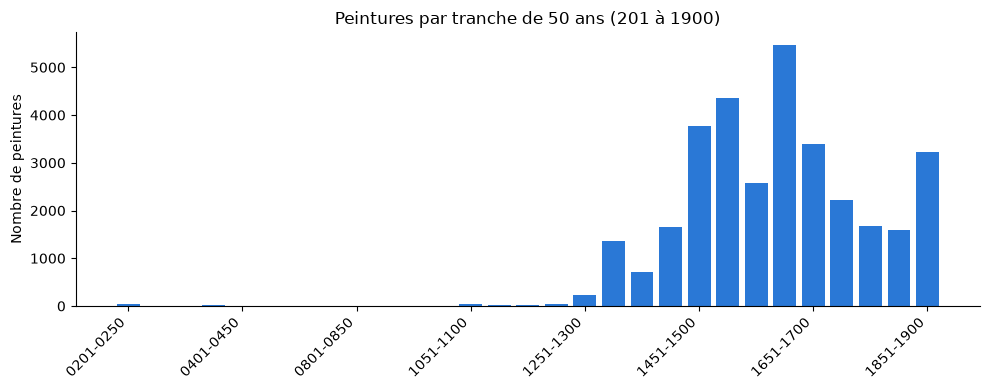

In [15]:
tf = paint["TIMEFRAME"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(tf.index, tf.values, color=BLUE, width=0.8)
ax.set_xticks(range(0, len(tf), 4))
ax.set_xticklabels(tf.index[::4], rotation=45, ha="right")
ax.set_ylabel("Nombre de peintures")
ax.set_title("Peintures par tranche de 50 ans (201 à 1900)")
plt.tight_layout()
plt.show()


**Résultat.** Le catalogue s'arrête en 1900, aucune œuvre moderne. Pic en
1601-1650 (baroque) ; quasi-absence avant 1300.


## 7. Artistes (`AUTHOR`)


In [16]:
author_vc = paint["AUTHOR"].value_counts()
print(f"{author_vc.size:,} artistes distincts pour {n_paint:,} peintures "
      f"({n_paint / author_vc.size:.1f} œuvres / artiste en moyenne)")
author_vc.head(12)


3,663 artistes distincts pour 32,438 peintures (8.9 œuvres / artiste en moyenne)


AUTHOR
GIOTTO di Bondone                 567
GOGH, Vincent van                 332
REMBRANDT Harmenszoon van Rijn    317
RUBENS, Peter Paul                308
RAFFAELLO Sanzio                  295
CRANACH, Lucas the Elder          291
TINTORETTO                        287
MICHELANGELO Buonarroti           278
TIZIANO Vecellio                  269
VERONESE, Paolo                   266
TIEPOLO, Giovanni Battista        249
GRECO, El                         245
Name: count, dtype: int64

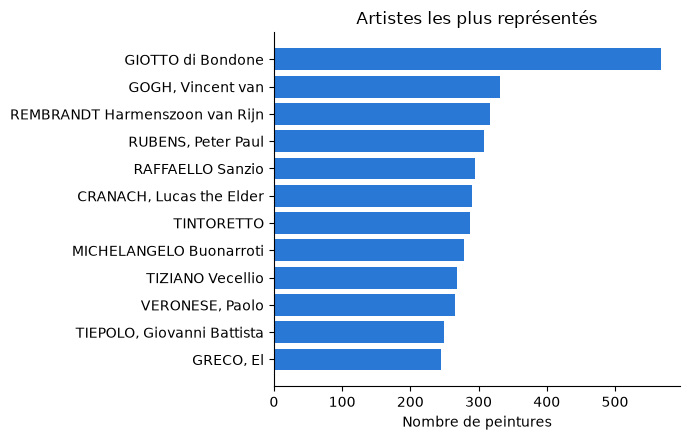

In [17]:
top_authors = author_vc.head(12)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top_authors.index[::-1], top_authors.values[::-1], color=BLUE)
ax.set_xlabel("Nombre de peintures")
ax.set_title("Artistes les plus représentés")
plt.tight_layout()
plt.show()


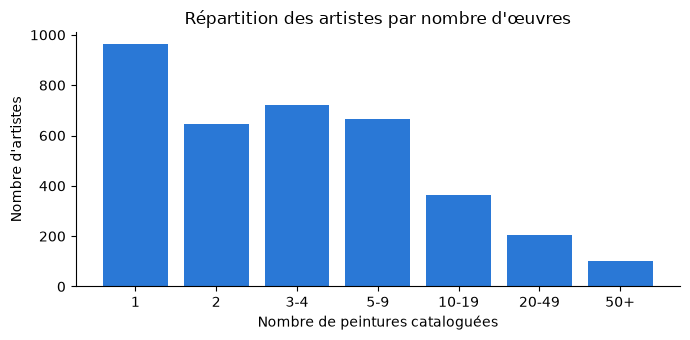

962 artistes (26%) n'ont qu'une seule peinture cataloguée.


In [18]:
bins = [0, 1, 2, 4, 9, 19, 49, 100000]
labels = ["1", "2", "3-4", "5-9", "10-19", "20-49", "50+"]
dist = pd.cut(author_vc, bins=bins, labels=labels).value_counts().reindex(labels)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(dist.index, dist.values, color=BLUE)
ax.set_xlabel("Nombre de peintures cataloguées")
ax.set_ylabel("Nombre d'artistes")
ax.set_title("Répartition des artistes par nombre d'œuvres")
plt.tight_layout()
plt.show()

print(f"{dist['1']} artistes ({dist['1'] / author_vc.size:.0%}) n'ont qu'une seule "
      "peinture cataloguée.")


**Résultat.** Distribution en loi de puissance : une poignée d'artistes très
documentés (Giotto, Van Gogh, Rembrandt, Rubens…) côtoient des milliers
d'artistes à une seule œuvre. Conditionnement par artiste réaliste pour une
douzaine de peintres seulement.


## 8. Technique, support et dimensions (`TECHNIQUE`)


In [19]:
medium = paint["TECHNIQUE"].str.split(",").str[0].str.strip()
medium_vc = medium.value_counts()
medium_vc.head(10)


TECHNIQUE
Oil on canvas       14743
Fresco               4488
Oil on panel         3337
Oil on wood          1942
Tempera on wood      1173
Tempera on panel      808
Oil on oak panel      773
Panel                 553
Oil on copper         476
Wood                  327
Name: count, dtype: int64

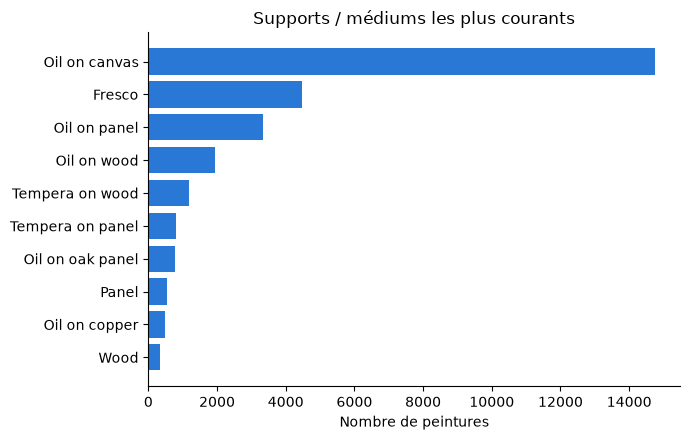

In [20]:
top_medium = medium_vc.head(10)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top_medium.index[::-1], top_medium.values[::-1], color=BLUE)
ax.set_xlabel("Nombre de peintures")
ax.set_title("Supports / médiums les plus courants")
plt.tight_layout()
plt.show()


In [21]:
DIM_RE = re.compile(r"(\d+(?:\.\d+)?)\s*x\s*(\d+(?:\.\d+)?)\s*cm", re.IGNORECASE)

def parse_dims(text):
    m = DIM_RE.search(str(text))
    return (float(m.group(1)), float(m.group(2))) if m else (None, None)

dims = paint["TECHNIQUE"].apply(parse_dims)
w = dims.apply(lambda t: t[0])
h = dims.apply(lambda t: t[1])

n_with_dims = w.notna().sum()
print(f"Dimensions exploitables : {n_with_dims:,} / {n_paint:,} ({n_with_dims / n_paint:.1%})")

ar = (w / h).dropna()
print()
print("Ratio largeur/hauteur :")
print(ar.describe())


Dimensions exploitables : 21,466 / 32,438 (66.2%)

Ratio largeur/hauteur :
count    21466.000000
mean         1.103071
std          0.600727
min          0.008772
25%          0.750000
50%          1.155844
75%          1.323529
max         37.500000
Name: TECHNIQUE, dtype: float64


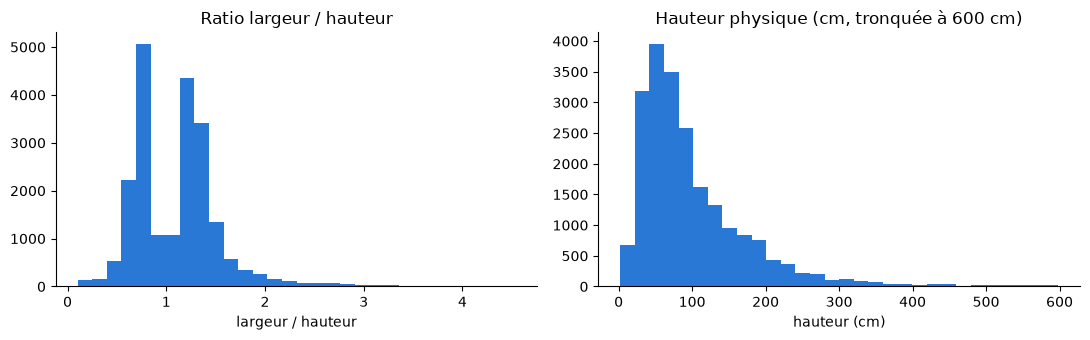

In [22]:
ar_clean = ar[(ar > 0.1) & (ar < 5)]  # on tronque les ratios extrêmes pour la lisibilité
h_clean = h[(h > 0) & (h < 600)].dropna()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(ar_clean, bins=30, color=BLUE)
axes[0].set_title("Ratio largeur / hauteur")
axes[0].set_xlabel("largeur / hauteur")

axes[1].hist(h_clean, bins=30, color=BLUE)
axes[1].set_title("Hauteur physique (cm, tronquée à 600 cm)")
axes[1].set_xlabel("hauteur (cm)")
plt.tight_layout()
plt.show()


**Résultat.** L'huile domine largement. Ratio largeur/hauteur de 0,01 à
37,5 ; 34 % des peintures sans dimension exploitable dans le texte.


## 9. Fiabilité du champ `DATE`


In [23]:
date = paint["DATE"].astype(str).str.strip()

date_quality = pd.Series({
    "Année exacte": date.str.match(r"^\d{4}$").sum(),
    "Plage d'années": date.str.contains(r"^\d{3,4}-\d{2,4}$").sum(),
    "Date approximative": date.str.contains(r"^c\.|ca\.", case=False, regex=True).sum(),
    "Décennie": date.str.contains(r"^\d{3,4}0s$").sum(),
    "Inconnue (\"-\")": (date == "-").sum(),
})
date_quality["Autre format"] = n_paint - date_quality.sum()
date_quality


Année exacte          10432
Plage d'années         9106
Date approximative     6732
Décennie               1572
Inconnue ("-")         3887
Autre format            709
dtype: int64

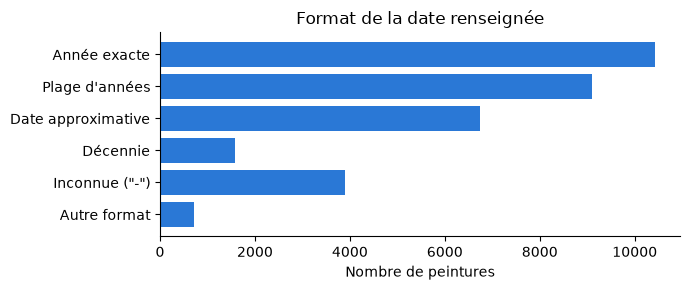

In [24]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(date_quality.index[::-1], date_quality.values[::-1], color=BLUE)
ax.set_xlabel("Nombre de peintures")
ax.set_title("Format de la date renseignée")
plt.tight_layout()
plt.show()


**Résultat.** 12 % des peintures marquées « date inconnue », seules 32 % ont
une année exacte. `TIMEFRAME` reste la colonne fiable pour filtrer par
époque.


## 10. Lieux de conservation (`LOCATION`)


In [25]:
loc_vc = paint["LOCATION"].value_counts()
print(f"{loc_vc.size:,} lieux distincts")
loc_vc.head(10)


2,284 lieux distincts


LOCATION
Private collection                      5437
Musée du Louvre, Paris                  1358
The Hermitage, St. Petersburg           1195
Metropolitan Museum of Art, New York     817
Museo del Prado, Madrid                  792
National Gallery, London                 767
Galleria degli Uffizi, Florence          744
Staatliche Museen, Berlin                643
Szépmûvészeti Múzeum, Budapest           548
Kunsthistorisches Museum, Vienna         478
Name: count, dtype: int64

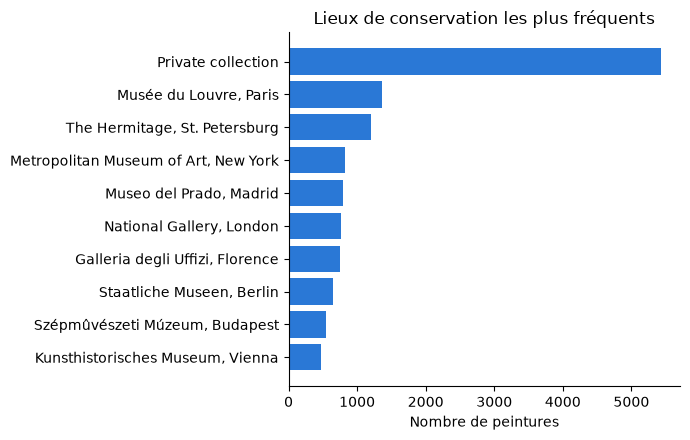


'Private collection' seul : 5,437 œuvres (16.8%)


In [26]:
top_loc = loc_vc.head(10)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top_loc.index[::-1], top_loc.values[::-1], color=BLUE)
ax.set_xlabel("Nombre de peintures")
ax.set_title("Lieux de conservation les plus fréquents")
plt.tight_layout()
plt.show()

print(f"\n'Private collection' seul : {loc_vc.get('Private collection', 0):,} œuvres "
      f"({loc_vc.get('Private collection', 0) / n_paint:.1%})")


**Résultat.** Les grands musées publics dominent le classement. « Private
collection » est la mention la plus fréquente (≈ 17 %).


## 11. Export du sous-ensemble peintures

**Résultat.** `data/paintings_only.csv` écrit (32 438 lignes).


In [27]:
paint.to_csv("data/paintings_only.csv", index=False)
print("Écrit :", "data/paintings_only.csv", f"({len(paint):,} lignes)")


Écrit : data/paintings_only.csv (32,438 lignes)


## 12. Conclusions — implications pour le projet GAN

- **Ce n'est pas (encore) un jeu d'images.** Les 32 438 lignes ne sont que des
  métadonnées pointant vers des pages wga.hu ; il faudra télécharger les images depuis la
  colonne `URL` (scraping respectueux : débit limité, conditions d'usage de la WGA à
  vérifier — reproduction autorisée à but non commercial/éducatif).
- **Corpus fortement déséquilibré.** Genre (religieux 42 %), école (italienne 42 %) et
  époque (rien après 1900) se cumulent. Un GAN inconditionnel reproduira avant tout des
  scènes religieuses italiennes baroques. À corriger par un GAN **conditionnel**
  (`TYPE`/`SCHOOL`/`TIMEFRAME`) ou un ré-échantillonnage.
- **Prétraitement image à prévoir.** Filtrer les formats extrêmes (ratio hors de
  ~0,4-2,5) avant resize ; choisir une stratégie de recadrage explicite (center-crop vs
  letterbox) plutôt qu'un simple resize qui déformerait les œuvres très allongées.
- **Colonnes à privilégier pour filtrer/conditionner :** `TIMEFRAME` (propre) plutôt que
  `DATE` (texte libre) ; `SCHOOL` et `TYPE` sont directement utilisables comme labels ;
  `AUTHOR` seulement pour une douzaine d'artistes très prolifiques (≥ 100 œuvres).
- **Le catalogue est propre au niveau métadonnées** (aucune ligne vide, aucun doublon),
  mais c'est un catalogue d'art ancien occidental (3ᵉ-19ᵉ siècle) dominé par la peinture
  religieuse italienne à l'huile — l'IA générative qui en résultera reflétera
  nécessairement cette composition, sauf correction explicite en amont.
